# STA 556 — Homework 4
## Simulation & Resampling
## Samuel Anoff Addo

IMPORTING LIBRARIES, SETTING SEED AND CREATING RANDOM GENERATOR

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 556

## PART ONE - MONTE CARLO PROBABILITY

TASK: Estimate one probability by simulation with at least 10,000 draws, report it, compare it with the true value, and explain Monte Carlo error.

In [2]:
## Creating Random Number Generator
rng = np.random.default_rng(SEED)

In [3]:
## Estimating Probability that a standard Normal random variable exceeds 1.645
##P(Z > 1.645).

M = 100_000
z = rng.normal(loc = 0, scale = 1, size = M)
indicator = (z > 1.645) 
p_hat = indicator.mean()

In [4]:
print(f"Estimated Probability : {p_hat:.5f}")

Estimated Probability : 0.05015


In [5]:
## Monte Carlo standard error
g = indicator.astype(int)                      # 0/1 values
mcse = g.std(ddof=1) / np.sqrt(len(g))

In [6]:
print(f"MCSE  : {mcse:.5f}")

MCSE  : 0.00069


In [7]:
## Comparing With Available Theoretical Value
Prob_True = 0.05
print(f"Theoretical Probability : {Prob_True:.5f}")
print(f"Absolute error : {abs(p_hat - Prob_True):.5f}")

Theoretical Probability : 0.05000
Absolute error : 0.00015


PART ONE:

Simulations used: 100,000.

Estimate: An estimate of P(Z > 1.645), where Z ~ Normal(0, 1), by simulation. This is the area under the standard normal curve to the right of 1.645.

Comparison With Theory: The theoretical probability is `0.05`. The estimate differs by `0.00015`, with a Monte Carlo Standard Error of `0.00069`.

**Result.**

| Quantity | Value |
|---|---|
| Monte Carlo estimate | 0.05015 |
| Monte Carlo standard error | 0.00069 |
| Exact value| 0.05 |
| Absolute error | 0.00015 |

**Monte Carlo error.** The estimate is itself random because it is based on a finite number of random draws; a different seed would give a slightly different value. The Monte Carlo standard error is computed as the sample standard deviation of the simulated 0s and 1s values divided by the square root of M. It measures the uncertainty in the estimate caused by using a finite number of simulations. It shrinks roughly like 1/sqrt(M) thus one divided by square root of M, so reducing the error by a factor of 10 requires about 100 times as many simulations.

## PART TWO — MONTE CARLO STABILITY

TASK: Repeat your Part 1 estimate at several simulation sizes, show a table or plot of how the estimate stabilizes, and explain why more simulations help.

In [8]:
## Simulation Sizes
sizes = [100_000 , 100 , 1_000, 10_000]
p_true = 0.05

## Creating Random Number Generator
rng = np.random.default_rng(SEED)

In [9]:
MonteCarlo = []
for m in sizes:
    z = rng.normal(loc=0, scale=1, size=m)
    g = (z > 1.645).astype(int)

    estimate = g.mean()
    mcse = g.std(ddof=1) / np.sqrt(len(g))

    MonteCarlo.append({
        "Simulation_Size": m,
        "Estimate": estimate,
        "MCSE": mcse,
        "Absolute_Error": abs(estimate - p_true),
    })

In [10]:
MonteCarlo_df = pd.DataFrame(MonteCarlo)
print(f"Exact value: {p_true:.5f}")
MonteCarlo_df

Exact value: 0.05000


,Simulation_Size,Estimate,MCSE,Absolute_Error
0,100000,0.05015,0.000690,0.00015
1,100,0.05000,0.021904,0.00000
2,1000,0.04900,0.006830,0.00100
3,10000,0.05460,0.002272,0.00460


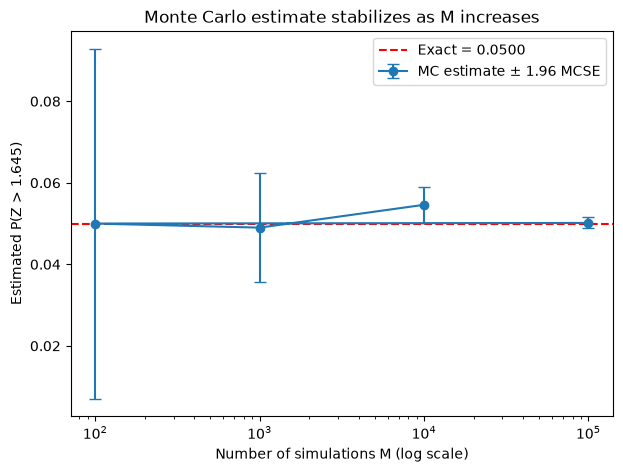

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(MonteCarlo_df["Simulation_Size"], MonteCarlo_df["Estimate"],
            yerr=1.96 * MonteCarlo_df["MCSE"],
            fmt="o-", capsize=4, label="MC estimate ± 1.96 MCSE")
ax.axhline(p_true, color="red", linestyle="--", label=f"Exact = {p_true:.4f}")

ax.set_xscale("log")
ax.set_xlabel("Number of simulations M (log scale)")
ax.set_ylabel("Estimated P(Z > 1.645)")
ax.set_title("Monte Carlo estimate stabilizes as M increases")
ax.legend()
plt.show()

PART TWO:

A Monte Carlo simulation is conducted to estimate P(Z > 1.645) with M = 100, 1,000, 10,000, and 100,000 simulations, using one random number generator throughout. A single random number generator is used throughout the simulations, and the resulting estimates are compared with the exact probability of 0.05.

| M | Estimate | MCSE | Absolute error |
|---|---|---|---|
| 100 | 0.05000 | 0.02190 | 0.00000 |
| 1,000 | 0.04900 | 0.00683 | 0.00100 |
| 10,000 | 0.05460 | 0.00227 | 0.00460 |
| 100,000 | 0.05015 | 0.00069 | 0.00015 |

**Results.** All four estimates are close to `0.05`. The Monte Carlo standard error falls from `0.0219` at M = 100 to `0.00069` at M = 100,000, dropping by a factor of about 3 for each tenfold increase in M, consistent with the 1/sqrt(M) rule.


**Why More Simulations Help:** Increasing the number of simulations improves the reliability of Monte Carlo estimates because it reduces random variation in the results. According to the Law of Large Numbers, as the number of simulations M increases, the sample average tends to get closer to the true expected value. A Monte Carlo estimate is an average of simulated values, so its error comes from random variation in the simulated draws. Averaging over more draws cancels more of the variations making the estimate more stable, and the standard error reduces roughly by 1/sqrt(M)
Therefore, reducing the Monte Carlo standard error by a factor of 10 requires approximately 100 times as many simulations.

## PART THREE — BOOTSTRAP

TASK: Choose a statistic, generate at least 5,000 bootstrap replicates, estimate the bootstrap standard error, build a percentile confidence interval, and interpret it.

In [12]:
## Reading the data from CSV file
ZenoMart_df = pd.read_csv("../data/raw/ZenoMart.csv")

In [13]:
print("Shape:", ZenoMart_df.shape)
print("Missing values:", int(ZenoMart_df.isna().sum().sum()))
print("Duplicate rows:", int(ZenoMart_df.duplicated().sum()))
print("Customer ID unique:", ZenoMart_df["Customer ID"].is_unique)
print()

Shape: (35, 13)
Missing values: 0
Duplicate rows: 0
Customer ID unique: True



In [14]:
ZenoMart_df.describe()

,Customer ID,Customer Date of Birth,Product Quantity,Cost Price,Selling Price,Purchase Date,Customer Loyalty Card
count,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000
mean,18.000000,32320.171429,21.685714,312.285714,397.714286,44307.628571,0.657143
std,10.246951,2198.990002,7.315461,428.572087,547.774029,577.195761,0.481594
min,1.000000,28307.000000,3.000000,10.000000,15.000000,42400.000000,0.000000
25%,9.500000,30652.500000,18.500000,40.000000,55.000000,44562.500000,0.000000
50%,18.000000,32227.000000,20.000000,100.000000,150.000000,44571.000000,1.000000
75%,26.500000,33824.500000,22.000000,400.000000,500.000000,44579.500000,1.000000
max,35.000000,36323.000000,40.000000,1500.000000,2000.000000,44593.000000,1.000000


**DATA DESCRIPTION**

**Source:** The data are the Zeno Mart customer transaction records (`ZenoMart.csv`).

**Structure:** The dataset has 35 transactions (rows) and 13 columns, including customer demographics (gender, location, date of birth), product information (category, type, name), quantity, cost price, selling price, purchase date, and loyalty-card status. There are no missing values or duplicate rows, and each Customer ID is unique.

**Variables used in this homework.**
- **Gender** (grouping variable): 18 female and 17 male customers.
- **Product Quantity** (outcome): number of units purchased in a transaction. 

**Choosen Statistic: Difference in Mean Product Quantity (Male − Female)**

 This analysis examines the average quantity of products purchased per transaction by male and female customers. Since quantity is not influenced by price outliers and both groups have relatively balanced sample sizes (approximately 17–18 observations each), the comparison focuses on the difference in their mean purchase quantities. 
 
 The key question is: How much more or less do male customers purchase per transaction compared with female customers, and how uncertain is this difference?

In [15]:
male = ZenoMart_df.loc[ZenoMart_df["Gender"] == "Male", "Product Quantity"].to_numpy()
female = ZenoMart_df.loc[ZenoMart_df["Gender"] == "Female", "Product Quantity"].to_numpy()


In [16]:
## A function to compute the difference in means between two samples
def diff_means(x, y):
    return np.mean(x) - np.mean(y)



In [17]:
observed = diff_means(male, female)
print(len(male), len(female))
print(f"Observed difference (Male - Female): {observed:.3f}")

17 18
Observed difference (Male - Female): 4.958


In [18]:
## Generate Bootstrap Replicates
rng = np.random.default_rng(556)
N_BOOT = 10_000      

Boot_MeanDiff = np.empty(N_BOOT)
for i in range(N_BOOT):
    male_b = rng.choice(male, size=len(male), replace=True)
    female_b = rng.choice(female, size=len(female), replace=True)
    Boot_MeanDiff[i] = diff_means(male_b, female_b)

In [19]:
## Bootstrap Standard Error and 95% Percentile Confidence Interval

Bootstrap_SE = Boot_MeanDiff.std(ddof=1)
ci_low, ci_high = np.quantile(Boot_MeanDiff, [0.025, 0.975])     # 95% percentile CI

print(f"Observed difference : {observed:.3f}")
print(f"Bootstrap mean      : {Boot_MeanDiff.mean():.3f}")
print(f"Bootstrap SE        : {Bootstrap_SE:.3f}")
print(f"95% percentile CI   : ({ci_low:.3f}, {ci_high:.3f})")

Observed difference : 4.958
Bootstrap mean      : 4.934
Bootstrap SE        : 2.291
95% percentile CI   : (0.618, 9.641)


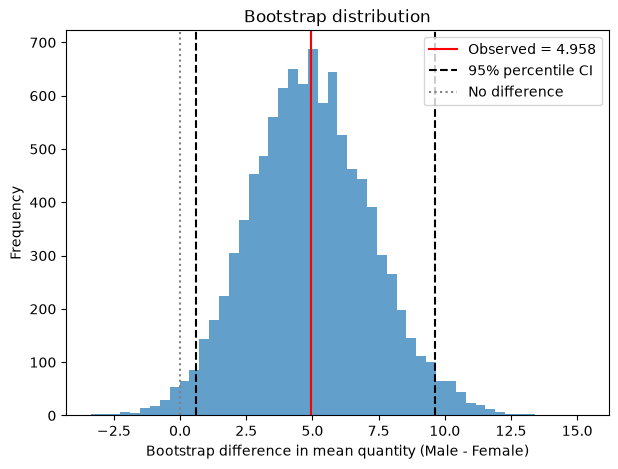

In [20]:
## Visualizing the Bootstrap Distribution of Mean Differences
plt.figure(figsize=(7, 5))
plt.hist(Boot_MeanDiff, bins=50, alpha=0.7)
plt.axvline(observed, color="red", label=f"Observed = {observed:.3f}")
plt.axvline(ci_low, color="black", linestyle="--", label="95% percentile CI")
plt.axvline(ci_high, color="black", linestyle="--")
plt.axvline(0, color="gray", linestyle=":", label="No difference")
plt.xlabel("Bootstrap difference in mean quantity (Male - Female)")
plt.ylabel("Frequency")
plt.title("Bootstrap distribution")
plt.legend()
plt.show()

PART THREE:

**Data and Statistic:** The Zeno Mart transaction data with n = 35, 17 male and 18 female customers. The statistic is the Difference in mean Product Quantity, Male − Female. The observed difference is `4.958`.


**Results.**

| Quantity | Value |
|---|---|
| Observed difference | `4.958` |
| Bootstrap standard error | `2.291` |
| 95% percentile CI | `(0.618, 9.641)` |


**Interpretation of the Interval:** Interpretation of the Interval: The bootstrap standard error of `2.291` indicates the typical amount of sampling variability in the estimated difference in mean quantity. Based on the bootstrap results, a plausible range for the true difference in mean quantity (Male − Female) is approximately `0.618` to `9.641` units. Since the interval excludes 0, the results suggest that male customers purchase larger quantities on average than female customers. 



## PART FOUR — PERMUTATION TEST

TASK: Define a test statistic, compute the observed value, build a permutation null distribution, calculate a Monte Carlo p-value with the +1 correction, interpret it, and explain how the permutation distribution differs from the bootstrap one.

H₀: Gender labels are exchangeable, meaning the distribution of Product Quantity is the same for male and female customers.

H₁: The mean quantity differs between the groups (two-sided).
Test statistic: the difference in means, Male − Female, the same statistic as in Part 3. 

**Hypotheses.**

$$H_0:\ \mu_M-\mu_F=0 \qquad \text{versus} \qquad H_1:\ \mu_M-\mu_F\neq 0$$

The permutation test assumes the stronger null that the group labels are exchangeable, i.e. $F_M=F_F$, so that every assignment of the 35 pooled values to groups of size 17 and 18 is equally likely under $H_0$.

**Test statistic.**
The difference in mean Product Quantity, Male − Female.

$$T=\bar{X}-\bar{Y}$$

The observed value is $t_{\text{obs}}=$ 4.958.

In [21]:
observed = diff_means(male, female)      
n_male = len(male)
print(f"Observed difference (Male - Female): {observed:.3f}")    

Observed difference (Male - Female): 4.958


In [22]:
## Null Distribution of Mean Differences Under the Null Hypothesis

N_PERM = 10_000
combined = np.concatenate([male, female])

null_distribution = np.empty(N_PERM)
for i in range(N_PERM):
    shuffled = rng.permutation(combined)
    null_distribution[i] = diff_means(shuffled[:n_male], shuffled[n_male:])

In [23]:
## Monte Carlo p-value for the two-sided test

extreme = np.sum(np.abs(null_distribution) >= abs(observed))
p_value = (1 + extreme) / (N_PERM + 1)

p_mcse = np.sqrt(p_value * (1 - p_value) / N_PERM)    # Monte Carlo error of the p-value itself

print(f"Permutations at least as extreme: {extreme}")
print(f"Monte Carlo p-value (two-sided, +1 correction): {p_value:.4f}")
print(f"Approx. Monte Carlo SE of the p-value: {p_mcse:.4f}")
print(f"Null distribution mean: {null_distribution.mean():.3f}")

Permutations at least as extreme: 431
Monte Carlo p-value (two-sided, +1 correction): 0.0432
Approx. Monte Carlo SE of the p-value: 0.0020
Null distribution mean: 0.009


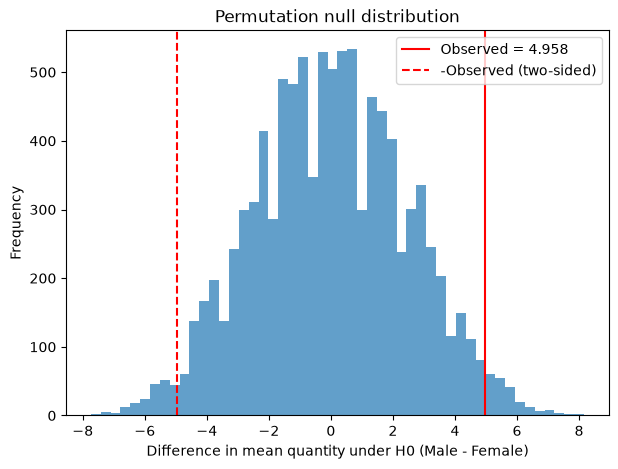

In [24]:
plt.figure(figsize=(7, 5))
plt.hist(null_distribution, bins=50, alpha=0.7)
plt.axvline(observed, color="red", label=f"Observed = {observed:.3f}")
plt.axvline(-observed, color="red", linestyle="--", label="-Observed (two-sided)")
plt.xlabel("Difference in mean quantity under H0 (Male - Female)")
plt.ylabel("Frequency")
plt.title("Permutation null distribution")
plt.legend()
plt.show()

PART FOUR


**Results.**

| Quantity | Value |
|---|---|
| Observed difference |  `4.958` |
| Monte Carlo p-value, (1 + count) / (10,000 + 1) |  `0.0432` |


**Interpretation:** The observed difference in mean Product Quantity is 4.958 units (Male − Female). Of 10,000 random relabelings of the data, 431 produced a difference at least as large in absolute value, giving a Monte Carlo p-value of (1 + 431)/(10,000 + 1) = 0.0432. In other words, if gender had no relationship with purchase quantity, a difference of 4.958 units or more in either direction would occur in about 4.3% of random assignments.
At the 0.05 significance level, this is just below the threshold, so I reject the null hypothesis that male and female quantities have the same distribution. The Monte Carlo standard error of the p-value is about 0.002. The null distribution is centered near 0 (mean 0.009), as expected when labels are shuffled under H₀, which confirms the permutation procedure worked as intended.

This result agrees with the bootstrap interval in Part 3, which also only just excluded 0. Both point to male customers buying somewhat larger quantities on average.  


**Permutation and Bootstrap.** 

Both methods resample the observed data, but they answer different questions.

Bootstrap: 


1. The bootstrap draws observations with replacement from the observed sample. The sample acts as an empirical approximation to the unknown population. Therefore, resampling with replacement mimics the process of repeatedly collecting new independent samples from that population.

2. It approximates the sampling distribution of a statistic that is, how an estimate would vary if we could repeatedly collect new datasets from the population.

3. The bootstrap does not require us to assume that the null hypothesis is true. Its distribution is generally centered near the observed statistic and is used to quantify uncertainty, particularly through the standard error and percentile confidence interval.

Permutation: 

1. A permutation test rearranges the observed values or group labels under the null hypothesis. For two independent groups, under the appropriate null hypothesis, the group labels are exchangeable. We therefore pool the observations and randomly reassign them to the groups without replacement. This means every observed value is used exactly once; only its group assignment changes.

2. It approximates the null distribution of the test statistic—the distribution we would expect if the null hypothesis were true. For a difference in means, this distribution is typically centered near the null value (zero). It is used for hypothesis testing by calculating the p-value: the proportion of permuted statistics that are at least as extreme as the observed statistic.


Why one cannot replace the other. Using the bootstrap distribution as the null distribution is a common permutation-test mistake because the bootstrap distribution is centered near the observed statistic, not the hypothesized null value. Similarly, sampling without replacement in an ordinary bootstrap is a mistake because it simply rearranges the original observations rather than generating new resamples.


In this homework. The statistic is the difference in mean Product Quantity between male and female customers (Male − Female), with an observed value of 4.958.

In Part 3 thus Bootstrap, I resampled the 17 male and 18 female quantities with replacement, separately within each group, 10,000 times. The resulting distribution is centered near the observed difference of 4.958, and its spread gives the bootstrap standard error (2.291) and the 95% percentile interval (0.618, 9.641). This quantifies the uncertainty in the estimated difference between the two groups.

In Part 4 thus Permutation test, I pooled all 35 quantities, shuffled their group labels without replacement, and reassigned them into groups of 17 and 18, 10,000 times, under the null hypothesis of no difference between the groups. The resulting distribution is centered near 0 (mean = 0.009), and 431 of the 10,000 shuffles produced a difference at least as large as 4.958 in absolute value, giving a p-value of 0.0432. This quantifies how surprising the observed difference would be if the null hypothesis were true.